# BT4012 Fraud Analytics Group 14: RGCN

## Libraries
Importing of necessary libraries

In [3]:
from pathlib import Path
import platform
import time

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.lines import Line2D

import torch
import torch.nn as nn
import torch.nn.functional as F
from sklearn.metrics import (average_precision_score, confusion_matrix, precision_recall_curve, roc_auc_score, roc_curve)
from sklearn.preprocessing import RobustScaler

## Configuration
Set folder paths, model settings (hidden size, dropout, learning rate, epochs), and the switches for first-time training, continuation model and history-first ranking

In [ ]:
# Folder paths
ROOT = Path.cwd().parent
DATA_DIR = ROOT / "data"
PROCESSED_DIR = DATA_DIR / "processed"
GRAPH_DIR = PROCESSED_DIR / "graph"
RESULTS_DIR = ROOT / "results"
FIG_DIR = RESULTS_DIR / "figures"
EMBEDDING_DIR = RESULTS_DIR / "rgcn_embeddings"

# Row keys, the relation to drop and the feature columns to leave out
KEYS = ["nodeID", "Year"]
DROP_RELATIONS = ["shared_related_org"]
DROP_FEATURE_SUFFIXES = ("_yoy", "_was_missing")

# Default network and training settings
HIDDEN_SIZE = 64
DROPOUT = 0.3
LEARNING_RATE = 0.005
WEIGHT_DECAY = 5e-4
MAX_EPOCHS = 300
PATIENCE = 30
SEED = 0
# The MLP has no skip connections, the R-GCN joins every layer's output
MLP_SETTINGS = dict(n_layers=2, skip=False)
RGCN_SETTINGS = dict(n_layers=2, skip=True)

# Final settings chosen in Steps B to F, these replace the defaults above
TRAINING_SETTINGS = dict(dropout=0.5, weight_decay=5e-3, stop_metric="pr_auc")
# Switches for the two-network setup and history-first ranking
FIRST_TIME_TRAINING = True
HISTORY_FIRST_RANKING = True
REFIT_ON_VALIDATION = False
CONTINUATION_MODEL = True
FEATURE_SET = "tabular + text"
CONTINUATION_FEATURE_SET = "tabular + text"
# Seeds for the final run and for the holdout tuning
N_SEEDS = 1
TUNING_SEEDS = [0, 1, 2]
# Share of companies flagged for review (top 5%)
FLAG_SHARE = 0.05

# Use the GPU when available
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

## Hardware
Python and PyTorch version check together with the CPU, RAM and GPU used

In [ ]:
# Machine used for the reported results
HARDWARE = {
    "cpu": "AMD Ryzen 7 7435HS, 8 cores / 16 threads",
    "ram": "28 GB DDR5",
    "gpu": "NVIDIA GeForce RTX 4060 Laptop GPU, 8 GB",
}
# Limit the number of CPU threads
torch.set_num_threads(8)

# Print software versions and hardware
print(f"python {platform.python_version()} | torch {torch.__version__} | CUDA build {torch.version.cuda}")
for part, description in HARDWARE.items():
    print(f"{part:<4} {description}")
# Confirm whether training will use the GPU
if DEVICE.type == "cuda":
    gpu = torch.cuda.get_device_properties(0)
    print(f"running on {gpu.name}, {gpu.total_memory / 1e9:.1f} GB")
else:
    print("WARNING: CUDA not available, running on CPU")

python 3.12.16 | torch 2.14.0+cu132 | CUDA build 13.2
cpu  AMD Ryzen 7 7435HS, 8 cores / 16 threads
ram  28 GB DDR5
gpu  NVIDIA GeForce RTX 4060 Laptop GPU, 8 GB
running on NVIDIA GeForce RTX 4060 Laptop GPU, 8.6 GB


## Loading pipeline outputs
Loads the splits, graph edges, degree features and text features made by earlier notebooks

In [ ]:
# Read a parquet or CSV file and make Year an integer
def read_table(path):
    table = pd.read_parquet(path) if path.suffix != ".csv" else pd.read_csv(path)
    return table.astype({"Year": "int64"})

# Outputs from the earlier notebooks
temporal_splits = read_table(DATA_DIR / "splits" / "temporal_splits.csv")
company_edges = read_table(GRAPH_DIR / "company_edges.parquet")
degree_features = read_table(GRAPH_DIR / "degree_features.csv")
text_features = read_table(PROCESSED_DIR / "text_features.parquet")
text_embeddings = read_table(PROCESSED_DIR / "text_embeddings.parquet")

# Test year of each split, plus the degree and text column names
TEST_YEAR_BY_SPLIT = (temporal_splits[temporal_splits["role"] == "test"].groupby("split")["Year"].first().astype(int).to_dict())
TEST_YEARS = list(TEST_YEAR_BY_SPLIT.values())
DEGREE_COLUMNS = [column for column in degree_features.columns if column not in KEYS]
TEXT_COLUMNS = {column for column in [*text_features.columns, *text_embeddings.columns] if column not in KEYS}

# Size of each loaded table
for name, table in {"temporal_splits": temporal_splits,
                    "company_edges": company_edges,
                    "degree_features": degree_features,
                    "text_features": text_features,
                    "text_embeddings": text_embeddings}.items():
    print(f"{name:<16} {len(table):>12,} rows  {table.shape[1]:>4} columns")
print("test year per split:", TEST_YEAR_BY_SPLIT)

temporal_splits       105,453 rows     5 columns
company_edges      13,157,706 rows     4 columns
degree_features        33,634 rows     6 columns
text_features          33,664 rows    10 columns
text_embeddings        33,664 rows    66 columns
test year per split: {0: 2019, 1: 2020, 2: 2021, 3: 2022}


## Edges
Drops the `shared_related_org` relation, maps every edge to a row number and counts the edges per relation

In [ ]:
# Drop unused relations and list the remaining ones
graph_edges = company_edges[~company_edges["relation"].isin(DROP_RELATIONS)]
RELATIONS = sorted(graph_edges["relation"].unique())

# One row per company-year, sorted by year, used as the node order
company_years = (temporal_splits[KEYS + ["Label"]].drop_duplicates(KEYS).sort_values(["Year", "nodeID"], ignore_index=True))
row_lookup = pd.MultiIndex.from_frame(company_years[KEYS])

# Turn a company ID and year into its node row number
def row_numbers(company_column):
    return row_lookup.get_indexer(pd.MultiIndex.from_arrays([graph_edges[company_column], graph_edges["Year"]]))

# Edges as node row numbers with a relation index
edge_list = pd.DataFrame({
    "source": row_numbers("source_id"),
    "target": row_numbers("target_id"),
    "relation": graph_edges["relation"].map({relation: i for i, relation in enumerate(RELATIONS)}).to_numpy(),
    "Year": graph_edges["Year"].to_numpy(),
})
# Every edge must point to a known company-year
assert (edge_list[["source", "target"]] >= 0).all().all(), "an edge points to a company-year with no features"

# Node count, edges kept and edges per relation
print(f"company-years: {len(company_years):,}")
print(f"edges: {len(company_edges):,} -> {len(edge_list):,} after dropping {', '.join(DROP_RELATIONS)}")
edge_list.groupby("relation").size().set_axis(RELATIONS).rename("edges").to_frame()

company-years: 33,664
edges: 13,157,706 -> 13,157,604 after dropping shared_related_org


,edges
Investment,141934
individual_investor_and_related_party,35128
org_investor_and_related_party,5468
related_party_transaction,20890
shared_auditor,8665326
shared_individual_investor,197878
shared_org_investor,451376
shared_related_individual,732956
shared_related_unlisted_firm,70146
shared_unlisted_investment,2757824


## Node features for each split
Joins tabular, text and degree features for one split and scales them

In [ ]:
# Join the label, tabular, text and degree features for one split
def load_split_table(split):
    rows = temporal_splits.loc[temporal_splits["split"] == split, KEYS + ["Label", "role"]]
    tabular = read_table(PROCESSED_DIR / "tabular_features_folds" / f"split_{split}")
    tfidf = read_table(PROCESSED_DIR / "text_tfidf" / f"split_{split}.parquet")

    table = rows
    for source in [tabular, text_features, text_embeddings, tfidf, degree_features]:
        table = table.merge(source, on=KEYS, how="left", validate="one_to_one")
    # No degree row means the company has no links
    table[DEGREE_COLUMNS] = table[DEGREE_COLUMNS].fillna(0)
    return table.sort_values(["Year", "nodeID"], ignore_index=True)

# True for text, embedding and TF-IDF columns
def is_text_column(column):
    return column in TEXT_COLUMNS or column.startswith("tfidf_")

# Pick the feature columns, leaving out year-on-year and missing-flag columns
def model_feature_columns(table, feature_set=None):
    columns = [column for column in table.columns if column not in KEYS + ["Label", "role"] and not column.endswith(DROP_FEATURE_SUFFIXES)]
    # Tabular-only run: remove the text columns
    if (feature_set or FEATURE_SET) == "tabular":
        columns = [column for column in columns if not is_text_column(column)]
    return columns

# Scale the features, fitting scalers on training rows only
def scale_features(table, columns):
    features = table[columns].astype("float64")
    train_rows = table["role"] == "train"
    text_columns = [column for column in columns if is_text_column(column)]

    # Log the link counts, then robust-scale the degree and text columns
    features[DEGREE_COLUMNS] = np.log1p(features[DEGREE_COLUMNS])
    for group in [DEGREE_COLUMNS, text_columns]:
        if not group:
            continue
        scaler = RobustScaler().fit(features.loc[train_rows, group])
        features[group] = scaler.transform(features[group])
    # Signed log shrinks very large values but keeps their sign
    features = np.sign(features) * np.log1p(features.abs())

    # Stop if any value is missing or infinite
    assert np.isfinite(features.to_numpy()).all(), "features contain NaN or inf"
    return features.to_numpy(np.float32)

## Fraud history
Adds 2 columns per company: whether it was fraudulent last year and whether it was listed last year

In [ ]:
# Last year's label for each company-year (missing if not listed last year)
def fraud_last_year(table):
    earlier = table[["nodeID", "Year", "Label"]].assign(Year=table["Year"] + 1)
    return table[KEYS].merge(earlier, on=KEYS, how="left", validate="one_to_one")["Label"]

# Add two columns: fraud last year, and listed last year
def add_fraud_history(table, features):
    last_year = fraud_last_year(table)
    history = np.column_stack([last_year.fillna(0), last_year.notna()]).astype(np.float32)
    return np.column_stack([features, history]).astype(np.float32)

# True for companies that were fraudulent last year
def repeat_candidates(table):
    return fraud_last_year(table).fillna(0).to_numpy() == 1

## Graph for each split
Builds one adjacency matrix per relation and packs the features and graph for a split

In [ ]:
# One sparse matrix per relation
def build_adjacency(edges, n_nodes):
    matrices = []
    for relation in range(len(RELATIONS)):
        chosen = edges[edges["relation"] == relation]
        receiver = torch.tensor(chosen["target"].to_numpy(), dtype=torch.long)
        sender = torch.tensor(chosen["source"].to_numpy(), dtype=torch.long)
        # Divide by the number of neighbours so each company receives an average
        n_links = torch.bincount(receiver, minlength=n_nodes).clamp(min=1).float()
        matrix = torch.sparse_coo_tensor(torch.stack([receiver, sender]), 1.0 / n_links[receiver], (n_nodes, n_nodes), check_invariants=False)
        matrices.append(matrix.coalesce().to(DEVICE))
    return matrices

# Scaled features plus the two fraud history columns
def split_features(table, feature_set=None):
    columns = model_feature_columns(table, feature_set)
    return add_fraud_history(table, scale_features(table, columns))

# Load one split: its table, features and graph up to the test year
def load_split(split, feature_set=None):
    test_year = TEST_YEAR_BY_SPLIT[split]
    table = load_split_table(split)
    n_nodes = len(table)

    # Check the rows line up with the node order used by the edges
    same_rows = (np.array_equal(table["nodeID"], company_years["nodeID"].iloc[:n_nodes]) and np.array_equal(table["Year"], company_years["Year"].iloc[:n_nodes]))
    assert same_rows, f"split {split}: rows are not every company-year up to {test_year}"
    assert table["Year"].max() == test_year, f"split {split}: last year is not the test year"

    features = split_features(table, feature_set)
    # Graph uses edges from 2014 up to the test year
    adjacency = build_adjacency(edge_list[edge_list["Year"] <= test_year], n_nodes)
    return table, features, adjacency

## Model
Defines the R-GCN layer and network
- NOTE: MLP is the same network just without the relations

In [ ]:
# One R-GCN layer: a weight for the company itself plus one weight per relation
class RGCNLayer(nn.Module):
    def __init__(self, in_size, out_size, n_relations):
        super().__init__()
        self.self_weight = nn.Linear(in_size, out_size)
        self.relation_weights = nn.ModuleList(nn.Linear(in_size, out_size, bias=False) for _ in range(n_relations))

    def forward(self, hidden, adjacency):
        output = self.self_weight(hidden)
        # Add the averaged neighbour messages from each relation
        for matrix, weight in zip(adjacency, self.relation_weights):
            output = output + torch.sparse.mm(matrix, weight(hidden))
        return output

# Full network: input layer, R-GCN layers, then a classifier (no relations gives the MLP)
class RGCN(nn.Module):
    def __init__(self, n_features, n_relations, n_layers=2, skip=False, hidden_size=HIDDEN_SIZE, dropout=DROPOUT):
        super().__init__()
        self.input_layer = nn.Linear(n_features, hidden_size)
        self.graph_layers = nn.ModuleList(RGCNLayer(hidden_size, hidden_size, n_relations) for _ in range(n_layers))
        self.skip = skip
        # With skip connections the classifier sees every layer's output
        classifier_size = hidden_size * (n_layers + 1) if skip else hidden_size
        self.classifier = nn.Linear(classifier_size, 1)
        self.dropout = nn.Dropout(dropout)

    # Hidden vectors for every company
    def embed(self, x, adjacency):
        hidden = self.dropout(F.relu(self.input_layer(x)))
        layer_outputs = [hidden]
        for layer in self.graph_layers:
            hidden = self.dropout(F.relu(layer(hidden, adjacency)))
            layer_outputs.append(hidden)
        return torch.cat(layer_outputs, dim=1) if self.skip else hidden

    # Fraud score (logit) for every company
    def forward(self, x, adjacency):
        return self.classifier(self.embed(x, adjacency)).squeeze(1)

## Training
Trains a model with weighted loss and early stopping, then scores every company. It also handles the first-time and continuation networks

In [ ]:
# Fraud probabilities for every company, with training switched off
def predict(model, x, adjacency):
    model.eval()
    with torch.no_grad():
        return torch.sigmoid(model(x, adjacency)).cpu().numpy()

# Train one network with weighted loss and early stopping
def train_model(x, y, adjacency, train_mask, val_mask=None, n_layers=2, skip=False, seed=SEED, dropout=DROPOUT,
                weight_decay=WEIGHT_DECAY, stop_metric="roc_auc", n_epochs=None, learning_rate=LEARNING_RATE, hidden_size=HIDDEN_SIZE):
    torch.manual_seed(seed)
    model = RGCN(x.shape[1], len(adjacency), n_layers, skip, hidden_size=hidden_size, dropout=dropout).to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate, weight_decay=weight_decay)
    # Weight frauds by the honest-to-fraud ratio so both classes count equally
    fraud_weight = (y[train_mask] == 0).sum() / (y[train_mask] == 1).sum()
    # Early stopping is used unless a fixed number of epochs is given
    early_stopping = n_epochs is None
    if early_stopping:
        val_rows = val_mask.cpu().numpy()
        val_labels = y.cpu().numpy()[val_rows]

    history = []
    best_score, best_epoch, best_state, epochs_without_improvement = -1.0, 0, None, 0
    # One full-graph training step per epoch
    for epoch in range(1, (n_epochs or MAX_EPOCHS) + 1):
        model.train()
        optimizer.zero_grad()
        logits = model(x, adjacency)
        loss = F.binary_cross_entropy_with_logits(logits[train_mask], y[train_mask], pos_weight=fraud_weight)
        loss.backward()
        optimizer.step()
        if not early_stopping:
            history.append({"epoch": epoch, "loss": loss.item()})
            continue

        # Score the validation year and keep the best epoch so far
        val_scores = predict(model, x, adjacency)[val_rows]
        record = {"epoch": epoch,
                  "loss": loss.item(),
                  "val_roc_auc": roc_auc_score(val_labels, val_scores),
                  "val_pr_auc": average_precision_score(val_labels, val_scores)}
        history.append(record)
        if record[f"val_{stop_metric}"] > best_score:
            best_score, best_epoch, epochs_without_improvement = record[f"val_{stop_metric}"], epoch, 0
            best_state = {name: value.detach().clone() for name, value in model.state_dict().items()}
        else:
            epochs_without_improvement += 1
            if epochs_without_improvement >= PATIENCE:
                break

    # Restore the weights from the best epoch
    if early_stopping:
        model.load_state_dict(best_state)
    else:
        best_epoch = n_epochs
    return model, best_epoch, pd.DataFrame(history)

# Train on years before the validation year, stop early on the validation year, then score everyone
def fit_and_predict(x, y, graph, years, test_year, seed=SEED, refit=False, usable_rows=None, **settings):
    usable = np.ones(len(years), dtype=bool) if usable_rows is None else usable_rows
    val_year = test_year - 1
    train_mask = torch.tensor(usable & (years < val_year), device=DEVICE)
    val_mask = torch.tensor(usable & (years == val_year), device=DEVICE)
    model, best_epoch, history = train_model(x, y, graph, train_mask, val_mask, seed=seed, **settings)
    # Optional: retrain on training and validation years for the same number of epochs
    if refit:
        refit_mask = torch.tensor(usable & (years < test_year), device=DEVICE)
        model, _, _ = train_model(x, y, graph, refit_mask, seed=seed, n_epochs=best_epoch, **settings)
    return model, predict(model, x, graph), best_epoch, history

# Two networks: one for first-time cases, one for last year's frauds
def fit_scores(x, y, graph, years, test_year, repeat, seed=SEED, refit=False, first_time=False, continuation=False, continuation_x=None, **settings):
    # The first-time network only trains on companies that were not fraudulent last year
    usable_rows = ~repeat if first_time else None
    model, network_scores, best_epoch, history = fit_and_predict(x, y, graph, years, test_year, seed, refit, usable_rows, **settings)
    scores = network_scores
    # Last year's frauds take their score from the continuation network
    if continuation:
        continuation_input = x if continuation_x is None else continuation_x
        _, continuation_scores, _, _ = fit_and_predict(continuation_input, y, graph, years, test_year, seed, refit, repeat, **settings)
        scores = np.where(repeat, continuation_scores, network_scores)
    return model, scores, network_scores, best_epoch, history

## Evaluation helpers
Functions for recall at 5%, history-first ranking and the test metrics for each model and year

In [ ]:
# Share of all frauds caught in the top 5% of scores
def recall_at_top(labels, scores, share=FLAG_SHARE):
    flagged = np.argsort(-scores)[:int(np.ceil(share * len(scores)))]
    return labels[flagged].sum() / labels.sum()

# History-first ranking: adding 1 puts last year's frauds at the top
def final_ranking(scores, repeat):
    return scores + repeat if HISTORY_FIRST_RANKING else scores

# Test metrics for one model and year
def evaluate(model_name, split, test_year, scores, labels, years, repeat,
             best_epoch=np.nan, seconds=np.nan, peak_gpu_gb=np.nan):
    test_rows, val_rows = years == test_year, years == test_year - 1
    # Split the test companies into first-time and repeat groups
    first_time = test_rows & ~repeat
    last_year_frauds = test_rows & repeat
    ranked = final_ranking(scores, repeat)
    return {"model": model_name,
            "split": split,
            "test_year": test_year,
            "best_epoch": best_epoch,
            "val_auc": np.nan if REFIT_ON_VALIDATION else roc_auc_score(labels[val_rows], ranked[val_rows]),
            "test_auc": roc_auc_score(labels[test_rows], ranked[test_rows]),
            "test_pr_auc": average_precision_score(labels[test_rows], ranked[test_rows]),
            "test_top5_recall": recall_at_top(labels[test_rows], ranked[test_rows]),
            "first_time_auc": roc_auc_score(labels[first_time], scores[first_time]),
            "first_time_pr_auc": average_precision_score(labels[first_time], scores[first_time]),
            "repeat_pr_auc": average_precision_score(labels[last_year_frauds], scores[last_year_frauds]),
            "test_fraud_rate": labels[test_rows].mean(),
            "seconds": seconds,
            "peak_gpu_gb": peak_gpu_gb}

# Save the R-GCN hidden vectors for every company-year
def save_hidden_vectors(model, x, adjacency, table, split, scores):
    model.eval()
    with torch.no_grad():
        hidden = model.embed(x, adjacency).cpu().numpy()
    val_year = TEST_YEAR_BY_SPLIT[split] - 1
    info = table[KEYS + ["Label"]].assign(
        role=np.select([table["Year"] < val_year, table["Year"] == val_year], ["train", "val"], "test"), rgcn_score=scores)
    vectors = pd.DataFrame(hidden, columns=[f"h{i}" for i in range(hidden.shape[1])])
    pd.concat([info, vectors], axis=1).to_parquet(EMBEDDING_DIR / f"split_{split}.parquet", index=False)

## Choosing settings on a holdout year
Functions that test candidate settings on the validation years over three seeds, and adopt a change only if it beats the seed noise

In [ ]:
# Measures compared on the holdout years
METRIC_NAMES = ["first_time_pr_auc", "repeat_pr_auc", "top5_recall", "first_time_roc_auc"]

# Holdout measures for one run
def holdout_metrics(labels, scores, repeat):
    first_time = ~repeat
    return {"first_time_pr_auc": average_precision_score(labels[first_time], scores[first_time]),
            "repeat_pr_auc": average_precision_score(labels[repeat], scores[repeat]),
            "top5_recall": recall_at_top(labels, final_ranking(scores, repeat)),
            "first_time_roc_auc": roc_auc_score(labels[first_time], scores[first_time])}

# Train each candidate with each seed, using the validation year as a stand-in test year
def run_holdout_experiment(candidates, seeds=TUNING_SEEDS):
    runs = []
    for split, test_year in TEST_YEAR_BY_SPLIT.items():
        holdout_year = test_year - 1
        table, features, adjacency = load_split(split)
        years = table["Year"].to_numpy()
        labels = table["Label"].to_numpy()
        repeat = repeat_candidates(table)
        holdout = years == holdout_year
        x = torch.tensor(features, device=DEVICE)
        y = torch.tensor(labels, dtype=torch.float32, device=DEVICE)

        # Candidate settings replace the matching final training settings
        for name, candidate in candidates.items():
            settings = {**TRAINING_SETTINGS, **candidate}
            refit = settings.pop("refit", REFIT_ON_VALIDATION)
            first_time = settings.pop("first_time", FIRST_TIME_TRAINING)
            continuation = settings.pop("continuation", CONTINUATION_MODEL)
            continuation_features = settings.pop("continuation_features", CONTINUATION_FEATURE_SET)
            continuation_x = torch.tensor(split_features(table, continuation_features), device=DEVICE)
            # Train the MLP and R-GCN, then average them for the ensemble
            for seed in seeds:
                scores = {}
                for model_name, graph, architecture in [("mlp", [], MLP_SETTINGS), ("rgcn", adjacency, RGCN_SETTINGS)]:
                    _, scores[model_name], _, _, _ = fit_scores(x, y, graph, years, holdout_year, repeat, seed, refit, first_time, continuation, continuation_x=continuation_x, **architecture, **settings)
                scores["ens"] = (scores["mlp"] + scores["rgcn"]) / 2
                for model_name, model_scores in scores.items():
                    runs.append({"candidate": name,
                                 "model": model_name,
                                 "split": split,
                                 "seed": seed,
                                 "labels": labels[holdout],
                                 "scores": model_scores[holdout],
                                 "repeat": repeat[holdout]})
            del continuation_x
        print(f"split {split} done (holdout year {holdout_year})")
        del x, y, adjacency
        if DEVICE.type == "cuda":
            torch.cuda.empty_cache()
    return pd.DataFrame(runs)

# Mean and standard deviation across seeds for each candidate and model
def summarise_holdout(runs):
    single = pd.DataFrame([{"candidate": run.candidate,
                            "model": run.model,
                            "seed": run.seed,
                            **holdout_metrics(run.labels, run.scores, run.repeat)} for run in runs.itertuples()])
    per_seed = single.groupby(["candidate", "model", "seed"], sort=False)[METRIC_NAMES].mean()
    summary = per_seed.groupby(level=["candidate", "model"], sort=False).agg(["mean", "std"])

    # Also score the average of all seeds' predictions
    averaged = pd.DataFrame([{"candidate": candidate,
                              "model": model_name,
                              **holdout_metrics(group["labels"].iloc[0],
                                                np.mean(np.stack(group["scores"].to_list()), axis=0),
                                                group["repeat"].iloc[0])}
                             for (candidate, model_name, _), group in runs.groupby(["candidate", "model", "split"], sort=False)])
    averaged = averaged.groupby(["candidate", "model"], sort=False)[METRIC_NAMES].mean()
    for metric in METRIC_NAMES:
        summary[(metric, "seed average")] = averaged[metric]
    return summary[[(metric, stat) for metric in METRIC_NAMES for stat in ["mean", "std", "seed average"]]].round(4)

# Adopt a change only if its gain beats the seed noise and recall at 5% does not drop
def compare_to(summary, baseline, model_name="ens", metric="first_time_pr_auc"):
    rows = summary.xs(model_name, level="model")
    pr_gain = rows[(metric, "mean")] - rows.loc[baseline, (metric, "mean")]
    recall_gain = rows[("top5_recall", "mean")] - rows.loc[baseline, ("top5_recall", "mean")]
    noise = rows.loc[baseline, (metric, "std")]
    return pd.DataFrame({f"{metric} gain": pr_gain,
                         "top-5% recall gain": recall_gain,
                         "noise (baseline std)": noise,
                         "adopt": (pr_gain > noise) & (recall_gain >= 0)}).round(4)

Steps B to F are commented out because they've already been run and their decisions are now built into the configuration settings. Each step compares several candidate settings across three seeds. Running them again on every `Run All` would repeat that work without changing the final model. They're kept in the notebook as a record of how the settings were chosen, and can be uncommented to rerun any of them.

### Step B: first-time fraud detection
Tests retraining on first-time cases only, early stopping on PR-AUC, and stronger dropout and weight decay

In [13]:
# STEP_B_CANDIDATES = {
#     "current": dict(first_time=False),
#     "first-time training": dict(first_time=True),
#     "first-time training, stop on PR-AUC": dict(first_time=True, stop_metric="pr_auc"),
#     "first-time training, dropout 0.5 + weight decay 5e-3": dict(first_time=True, stop_metric="pr_auc", dropout=0.5, weight_decay=5e-3),
#     "dropout 0.5 + weight decay 5e-3": dict(first_time=False, stop_metric="pr_auc", dropout=0.5, weight_decay=5e-3),
# }
# step_b_runs = run_holdout_experiment(STEP_B_CANDIDATES)
# step_b = summarise_holdout(step_b_runs)
# display(step_b)
# compare_to(step_b, "current")

### Step C: refit on the validation year
Tests retraining on the training and validation years together

In [14]:
# STEP_C_CANDIDATES = {
#     "step B winner": dict(refit=False),
#     "refit on validation year": dict(refit=True),
# }
# step_c_runs = run_holdout_experiment(STEP_C_CANDIDATES)
# step_c = summarise_holdout(step_c_runs)
# display(step_c)
# compare_to(step_c, "step B winner")

### Step D: learning rate and network size
Tests lower learning rates and a smaller hidden size

In [15]:
# STEP_D_CANDIDATES = {
#     "current": {},
#     "learning rate 0.002": dict(learning_rate=0.002),
#     "learning rate 0.001": dict(learning_rate=0.001),
#     "hidden size 32": dict(hidden_size=32),
#     "learning rate 0.001 + hidden size 32": dict(learning_rate=0.001, hidden_size=32),
# }
# step_d_runs = run_holdout_experiment(STEP_D_CANDIDATES)
# step_d = summarise_holdout(step_d_runs)
# display(step_d)
# compare_to(step_d, "current")

### Step E: continuation model for last year's frauds
Tests a separate network for companies that were fraudulent last year

In [16]:
# STEP_E_CANDIDATES = {
#     "step D winner": dict(continuation=False),
#     "continuation model": dict(continuation=True),
# }
# step_e_runs = run_holdout_experiment(STEP_E_CANDIDATES)
# step_e = summarise_holdout(step_e_runs)
# display(step_e)
# compare_to(step_e, "step D winner", metric="repeat_pr_auc")

### Step F: continuation model on tabular features only
Tests the network without text features

In [30]:
# STEP_F_CANDIDATES = {
#     "current": dict(continuation_features="tabular + text"),
#     "continuation model on tabular only": dict(continuation_features="tabular"),
# }
# step_f_runs = run_holdout_experiment(STEP_F_CANDIDATES)
# step_f = summarise_holdout(step_f_runs)
# display(step_f)
# compare_to(step_f, "current", metric="repeat_pr_auc")

## Walk-forward experiments
Trains the MLP and R-GCN for each test year (2019-2022), build the ensemble, saves the results and predictions, and saves the R-GCN hidden vectors

In [ ]:
# Create the output folders
RESULTS_DIR.mkdir(exist_ok=True)
EMBEDDING_DIR.mkdir(parents=True, exist_ok=True)

# Collect results across all four splits
results, predictions, histories, split_summary = [], [], [], []
# One split per test year (2019 to 2022)
for split, test_year in TEST_YEAR_BY_SPLIT.items():
    val_year = test_year - 1
    # Load the split and mark last year's frauds
    table, features, adjacency = load_split(split)
    years = table["Year"].to_numpy()
    labels = table["Label"].to_numpy()
    repeat = repeat_candidates(table)
    test_rows = years == test_year

    # Move features and labels to the GPU
    x = torch.tensor(features, device=DEVICE)
    y = torch.tensor(labels, dtype=torch.float32, device=DEVICE)
    continuation_x = torch.tensor(split_features(table, CONTINUATION_FEATURE_SET), device=DEVICE)

    # Record the split's size and fraud counts
    n_edges = sum(matrix._nnz() for matrix in adjacency)
    split_summary.append({"split": split,
                          "test_year": test_year,
                          "nodes": len(table),
                          "edges": n_edges,
                          "features": features.shape[1],
                          "train_fraud": int(labels[years < val_year].sum()),
                          "val_fraud": int(labels[years == val_year].sum()),
                          "test_fraud": int(labels[test_rows].sum()),
                          "test_first_time_fraud": int(labels[test_rows & ~repeat].sum())})
    print(f"split {split}: {len(table):,} nodes, {n_edges:,} edges, {features.shape[1]:,} features")

    # Train the MLP (no graph) and the R-GCN
    scores, network_scores = {}, {}
    for model_name, graph, settings in [("mlp", [], MLP_SETTINGS), ("rgcn", adjacency, RGCN_SETTINGS)]:
        if DEVICE.type == "cuda":
            torch.cuda.reset_peak_memory_stats()
        start = time.perf_counter()
        seed_scores, seed_network_scores, best_epochs = [], [], []
        # Train with each seed and average the scores
        for seed in range(SEED, SEED + N_SEEDS):
            model, model_scores, model_network_scores, best_epoch, history = fit_scores(x, y, graph, years, test_year, repeat, seed, REFIT_ON_VALIDATION, FIRST_TIME_TRAINING, CONTINUATION_MODEL, continuation_x=continuation_x, **settings, **TRAINING_SETTINGS)
            seed_scores.append(model_scores)
            seed_network_scores.append(model_network_scores)
            best_epochs.append(best_epoch)
            # Keep the first seed's training curve and R-GCN hidden vectors
            if seed == SEED:
                histories.append(history.assign(model=model_name, test_year=test_year))
                if model_name == "rgcn":
                    save_hidden_vectors(model, x, graph, table, split, model_scores)
        # Average over seeds and record the time and GPU memory used
        scores[model_name] = np.mean(seed_scores, axis=0)
        network_scores[model_name] = np.mean(seed_network_scores, axis=0)
        seconds = time.perf_counter() - start
        peak_gpu_gb = torch.cuda.max_memory_allocated() / 1e9 if DEVICE.type == "cuda" else np.nan

        # Test metrics for this model and year
        result = evaluate(model_name, split, test_year, scores[model_name], labels, years, repeat, np.mean(best_epochs), seconds, peak_gpu_gb)
        results.append(result)
        print(f"  {model_name:<5} {test_year}  epoch {np.mean(best_epochs):>5.0f}  test AUC {result['test_auc']:.4f}  "
              f"PR-AUC {result['test_pr_auc']:.4f}  top-5% recall {result['test_top5_recall']:.3f}  "
              f"first-time PR-AUC {result['first_time_pr_auc']:.4f}  {seconds:.0f}s  {peak_gpu_gb:.2f} GB")

    # Ensemble: average of the MLP and R-GCN scores
    scores["ens"] = (scores["mlp"] + scores["rgcn"]) / 2
    network_scores["ens"] = (network_scores["mlp"] + network_scores["rgcn"]) / 2
    result = evaluate("ens", split, test_year, scores["ens"], labels, years, repeat)
    results.append(result)
    print(f"  {'ens':<5} {test_year}  test AUC {result['test_auc']:.4f}  PR-AUC {result['test_pr_auc']:.4f}  "
          f"top-5% recall {result['test_top5_recall']:.3f}  first-time PR-AUC {result['first_time_pr_auc']:.4f}")

    # Keep the test-year scores for the charts and diagnostics
    for model_name, model_scores in scores.items():
        predictions.append(table.loc[test_rows, ["nodeID", "Year", "Label"]].assign(model=model_name, score=final_ranking(model_scores, repeat)[test_rows], model_score=model_scores[test_rows], network_score=network_scores[model_name][test_rows]))

    # Free GPU memory before the next split
    del x, y, continuation_x, adjacency, graph, model
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()

# Combine and save the results
results = pd.DataFrame(results).round(4)
predictions = pd.concat(predictions, ignore_index=True)
histories = pd.concat(histories, ignore_index=True)
split_summary = pd.DataFrame(split_summary)

results.to_csv(RESULTS_DIR / "rgcn_results.csv", index=False)
predictions.to_csv(RESULTS_DIR / "rgcn_predictions.csv", index=False)
# Average test metrics per model
print()
print(results.groupby("model", sort=False)[["test_auc", "test_pr_auc", "test_top5_recall", "first_time_pr_auc", "repeat_pr_auc"]].mean().round(4))
results

split 0: 19,494 nodes, 7,802,746 edges, 729 features
  mlp   2019  epoch     8  test AUC 0.9313  PR-AUC 0.6447  top-5% recall 0.650  first-time PR-AUC 0.0450  1s  0.33 GB
  rgcn  2019  epoch     8  test AUC 0.9296  PR-AUC 0.6570  top-5% recall 0.673  first-time PR-AUC 0.0477  8s  0.63 GB
  ens   2019  test AUC 0.9317  PR-AUC 0.6563  top-5% recall 0.673  first-time PR-AUC 0.0471
split 1: 23,763 nodes, 9,345,718 edges, 729 features
  mlp   2020  epoch    11  test AUC 0.8936  PR-AUC 0.5424  top-5% recall 0.638  first-time PR-AUC 0.0607  1s  0.39 GB
  rgcn  2020  epoch    12  test AUC 0.8924  PR-AUC 0.5534  top-5% recall 0.638  first-time PR-AUC 0.0605  10s  0.77 GB
  ens   2020  test AUC 0.8943  PR-AUC 0.5595  top-5% recall 0.633  first-time PR-AUC 0.0606
split 2: 28,532 nodes, 11,163,822 edges, 729 features
  mlp   2021  epoch     8  test AUC 0.9161  PR-AUC 0.5999  top-5% recall 0.754  first-time PR-AUC 0.0265  1s  0.47 GB
  rgcn  2021  epoch    18  test AUC 0.9115  PR-AUC 0.5751  top-5%

,model,split,test_year,best_epoch,val_auc,test_auc,test_pr_auc,test_top5_recall,first_time_auc,first_time_pr_auc,repeat_pr_auc,test_fraud_rate,seconds,peak_gpu_gb
0,mlp,0,2019,8.0,0.9077,0.9313,0.6447,0.6495,0.7705,0.0450,0.7806,0.0561,0.7706,0.3302
1,rgcn,0,2019,8.0,0.9138,0.9296,0.6570,0.6729,0.7628,0.0477,0.7932,0.0561,8.1746,0.6309
2,ens,0,2019,NaN,0.9121,0.9317,0.6563,0.6729,0.7711,0.0471,0.7930,0.0561,NaN,NaN
3,mlp,1,2020,11.0,0.9401,0.8936,0.5424,0.6377,0.7370,0.0607,0.7258,0.0485,0.8731,0.3933
4,rgcn,1,2020,12.0,0.9341,0.8924,0.5534,0.6377,0.7334,0.0605,0.7470,0.0485,9.5962,0.7708
5,ens,1,2020,NaN,0.9378,0.8943,0.5595,0.6329,0.7385,0.0606,0.7533,0.0485,NaN,NaN
6,mlp,2,2021,8.0,0.8925,0.9161,0.5999,0.7541,0.7020,0.0265,0.7422,0.0384,1.0084,0.4668
7,rgcn,2,2021,18.0,0.8961,0.9115,0.5751,0.7486,0.6848,0.0208,0.7167,0.0384,13.7203,0.9452
8,ens,2,2021,NaN,0.8986,0.9161,0.5905,0.7486,0.7024,0.0230,0.7333,0.0384,NaN,NaN
9,mlp,3,2022,5.0,0.9169,0.9639,0.5645,0.8211,0.8606,0.0318,0.6528,0.0240,0.9090,0.5482


### Split summary
Table of companies, edges, features and fraud counts per split

In [ ]:
# Size and fraud counts of each split
split_summary

,split,test_year,nodes,edges,features,train_fraud,val_fraud,test_fraud,test_first_time_fraud
0,0,2019,19494,7802746,729,607,225,214,56
1,1,2020,23763,9345718,729,832,214,207,76
2,2,2021,28532,11163822,729,1046,207,183,47
3,3,2022,33664,13157604,729,1253,183,123,25


## Tabular only vs Tabular + Text
Reruns the models with and without the text features and compares the results

In [ ]:
# Compare tabular-only features with tabular + text
FEATURE_SETS = ["tabular", "tabular + text"]

feature_rows = []
# Train both models on each feature set for every split
for split, test_year in TEST_YEAR_BY_SPLIT.items():
    for feature_set in FEATURE_SETS:
        table, features, adjacency = load_split(split, feature_set)
        years = table["Year"].to_numpy()
        labels = table["Label"].to_numpy()
        repeat = repeat_candidates(table)
        x = torch.tensor(features, device=DEVICE)
        y = torch.tensor(labels, dtype=torch.float32, device=DEVICE)

        scores = {}
        for model_name, graph, settings in [("mlp", [], MLP_SETTINGS), ("rgcn", adjacency, RGCN_SETTINGS)]:
            _, scores[model_name], _, _, _ = fit_scores(x, y, graph, years, test_year, repeat, SEED, REFIT_ON_VALIDATION, FIRST_TIME_TRAINING, CONTINUATION_MODEL, **settings, **TRAINING_SETTINGS)
        # Ensemble and test metrics
        scores["ens"] = (scores["mlp"] + scores["rgcn"]) / 2
        for model_name, model_scores in scores.items():
            feature_rows.append({"feature_set": feature_set,
                                 "features": features.shape[1],
                                 **evaluate(model_name, split, test_year, model_scores, labels, years, repeat)})

        # Free GPU memory
        del x, y, adjacency
        if DEVICE.type == "cuda":
            torch.cuda.empty_cache()
    print(f"split {split} done")

# Save and show the average results per feature set and model
feature_comparison = pd.DataFrame(feature_rows)
feature_comparison.to_csv(RESULTS_DIR / "feature_set_comparison.csv", index=False)
(feature_comparison
 .groupby(["feature_set", "model"], sort=False)[["features", "test_auc", "test_pr_auc", "test_top5_recall", "first_time_pr_auc", "repeat_pr_auc"]]
 .mean()
 .round(4))

split 0 done
split 1 done
split 2 done
split 3 done


features  test_auc  test_pr_auc  test_top5_recall  \
feature_set    model                                                      
tabular        mlp       557.0    0.9240       0.5966            0.7130   
               rgcn      557.0    0.9252       0.5973            0.7153   
               ens       557.0    0.9253       0.5992            0.7183   
tabular + text mlp       729.0    0.9262       0.5879            0.7156   
               rgcn      729.0    0.9244       0.5879            0.7242   
               ens       729.0    0.9267       0.5938            0.7189   

                      first_time_pr_auc  repeat_pr_auc  
feature_set    model                                    
tabular        mlp               0.0410         0.7401  
               rgcn              0.0413         0.7371  
               ens               0.0405         0.7405  
tabular + text mlp               0.0410         0.7254  
               rgcn              0.0417         0.7267  
               ens               0.0417         0.7337

## Visualising the metrics
Sets up the chart colours, labels and helper functions

In [ ]:
# Folder for saved charts
FIG_DIR.mkdir(parents=True, exist_ok=True)

# Models, colours and display names used in every chart
MODELS = ["mlp", "rgcn", "ens"]
TRAINED_MODELS = ["mlp", "rgcn"]
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
INK, INK_2, GRID, MUTED = "#0b0b0b", "#52514e", "#e6e5e1", "#b8b7b1"
COLORS = {"mlp": BLUE, "rgcn": ORANGE, "ens": AQUA}
NAMES = {"mlp": "MLP (no graph)", "rgcn": "RGCN", "ens": "MLP + RGCN"}

# Shared chart style
plt.rcParams.update({
    "figure.dpi": 110,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": MUTED,
    "axes.labelcolor": INK_2,
    "axes.titlecolor": INK,
    "axes.titlesize": 11,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.grid": True,
    "axes.axisbelow": True,
    "grid.color": GRID,
    "grid.linewidth": 0.6,
    "xtick.color": INK_2,
    "ytick.color": INK_2,
    "font.size": 9.5,
    "legend.frameon": False,
    "lines.linewidth": 2,
})

# Save a chart to the figures folder
def save_fig(fig, name):
    fig.savefig(FIG_DIR / f"{name}.png", dpi=200, bbox_inches="tight")

# Dashed line showing a random model
def draw_random_line(ax, x, y, label):
    ax.plot(x, y, linestyle="--", linewidth=1.2, color=INK_2, label=label)

# Test predictions for one model and year
def predictions_for(model_name, year):
    return predictions[(predictions["model"] == model_name) & (predictions["Year"] == year)]

### Headline metrics per test year
Line charts of ROC-AUC and PR-AUC for each test year

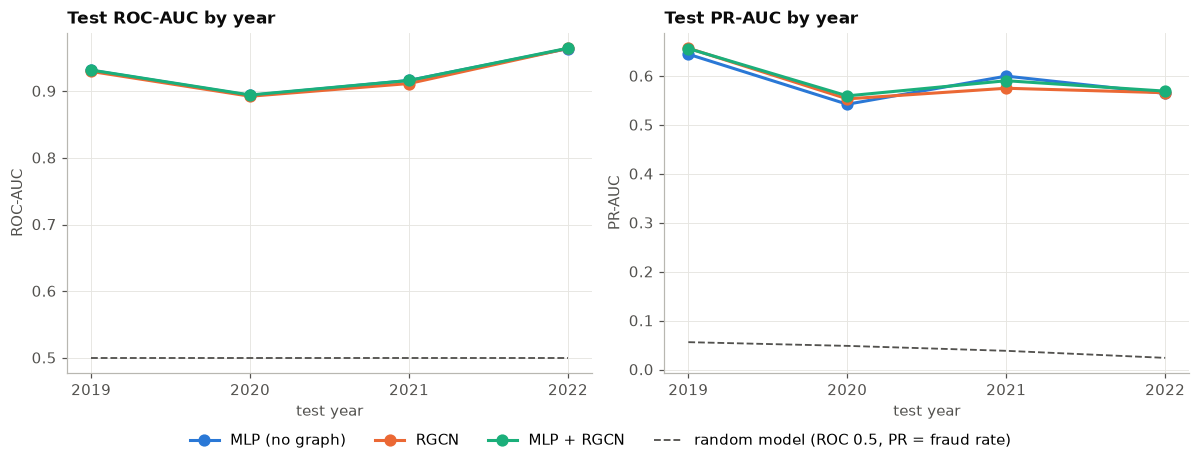

In [ ]:
# ROC-AUC and PR-AUC per test year, with the random baseline
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
fraud_rate = results[results["model"] == "mlp"].sort_values("test_year")
for ax, metric, title in [(axes[0], "test_auc", "ROC-AUC"), (axes[1], "test_pr_auc", "PR-AUC")]:
    for model_name in MODELS:
        rows = results[results["model"] == model_name].sort_values("test_year")
        ax.plot(rows["test_year"], rows[metric], marker="o", markersize=7, color=COLORS[model_name], label=NAMES[model_name])
    random_level = [0.5] * len(fraud_rate) if metric == "test_auc" else fraud_rate["test_fraud_rate"]
    draw_random_line(ax, fraud_rate["test_year"], random_level, "random model")
    ax.set(title=f"Test {title} by year", xlabel="test year", ylabel=title, xticks=TEST_YEARS)

# Shared legend under both charts
handles, labels = axes[0].get_legend_handles_labels()
labels[-1] = "random model (ROC 0.5, PR = fraud rate)"
fig.legend(handles, labels, loc="lower center", ncol=len(handles), bbox_to_anchor=(0.5, -0.06))
fig.tight_layout()
save_fig(fig, "metrics_by_year")
plt.show()

### ROC and precision-recall curves
ROC and PR curves for each model and year

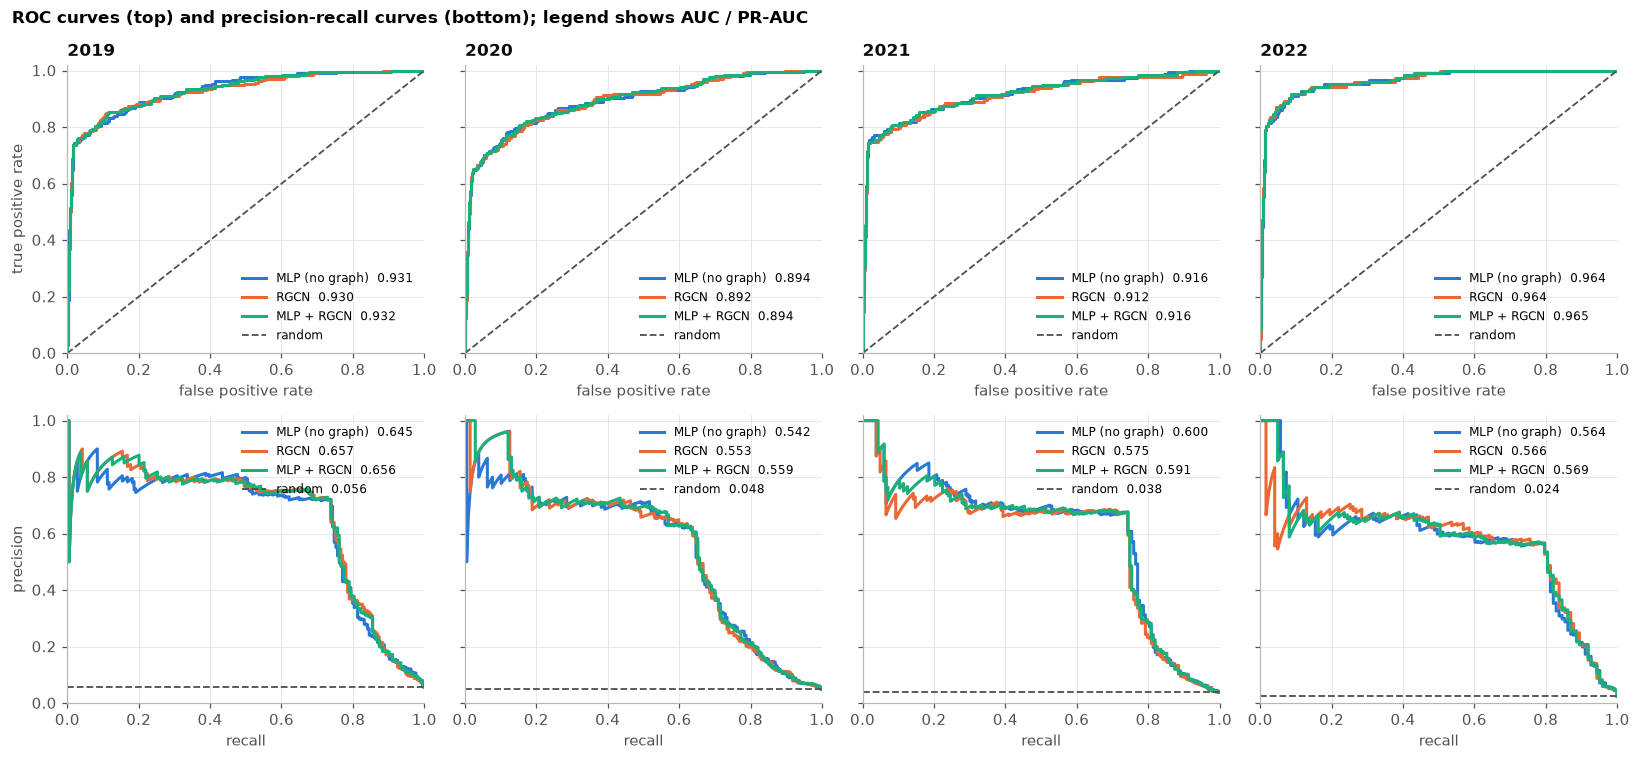

In [ ]:
# Top row: ROC curves. Bottom row: precision-recall curves
fig, axes = plt.subplots(2, len(TEST_YEARS), figsize=(15, 7), sharex=True, sharey="row")
for column, year in enumerate(TEST_YEARS):
    roc_ax, pr_ax = axes[0, column], axes[1, column]
    for model_name in MODELS:
        rows = predictions_for(model_name, year)
        false_positive_rate, true_positive_rate, _ = roc_curve(rows["Label"], rows["score"])
        precision, recall, _ = precision_recall_curve(rows["Label"], rows["score"])
        roc_auc = roc_auc_score(rows["Label"], rows["score"])
        pr_auc = average_precision_score(rows["Label"], rows["score"])
        roc_ax.plot(false_positive_rate, true_positive_rate, color=COLORS[model_name], label=f"{NAMES[model_name]}  {roc_auc:.3f}")
        pr_ax.plot(recall, precision, color=COLORS[model_name], label=f"{NAMES[model_name]}  {pr_auc:.3f}")

    # Random baseline: the diagonal for ROC, the fraud rate for PR
    year_fraud_rate = rows["Label"].mean()
    draw_random_line(roc_ax, [0, 1], [0, 1], "random")
    draw_random_line(pr_ax, [0, 1], [year_fraud_rate, year_fraud_rate], f"random  {year_fraud_rate:.3f}")
    roc_ax.set(title=str(year), xlim=(0, 1), ylim=(0, 1.02), xlabel="false positive rate")
    roc_ax.xaxis.set_tick_params(labelbottom=True)
    pr_ax.set(xlabel="recall", ylim=(0, 1.02))
    roc_ax.legend(fontsize=8, loc="lower right")
    pr_ax.legend(fontsize=8, loc="upper right")

axes[0, 0].set_ylabel("true positive rate")
axes[1, 0].set_ylabel("precision")
fig.suptitle("ROC curves (top) and precision-recall curves (bottom); legend shows AUC / PR-AUC", x=0.01, ha="left", fontsize=11, fontweight="bold")
fig.tight_layout()
save_fig(fig, "roc_pr_curves")
plt.show()

### Frauds caught when reviewing the top-scored companies
Share of frauds caught as more companies are reviewed, from the highest score down

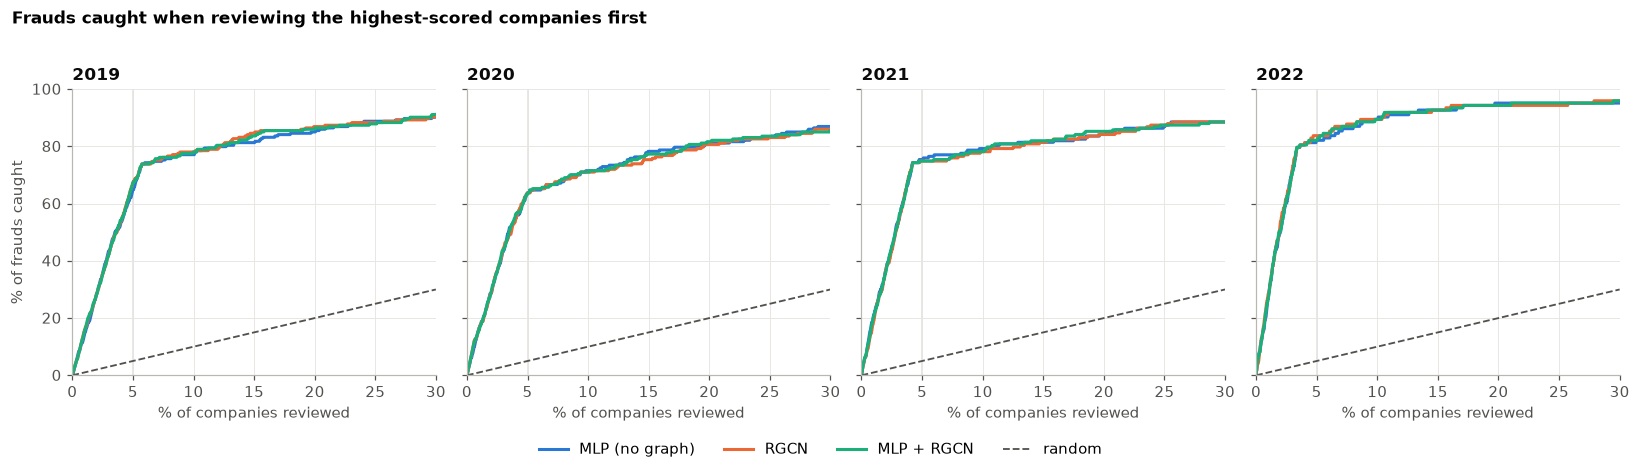

In [ ]:
# Share of frauds caught as more top-scored companies are reviewed
fig, axes = plt.subplots(1, len(TEST_YEARS), figsize=(15, 3.8), sharey=True)
for ax, year in zip(axes, TEST_YEARS):
    for model_name in MODELS:
        ranked_labels = (predictions_for(model_name, year).sort_values("score", ascending=False)["Label"].to_numpy())
        share_reviewed = np.arange(1, len(ranked_labels) + 1) / len(ranked_labels)
        share_caught = np.cumsum(ranked_labels) / ranked_labels.sum()
        ax.plot(share_reviewed * 100, share_caught * 100, color=COLORS[model_name], label=NAMES[model_name])
    draw_random_line(ax, [0, 30], [0, 30], "random")
    # Mark the 5% review level
    ax.axvline(5, color=GRID, linewidth=1.2, zorder=0)
    ax.set(title=str(year), xlim=(0, 30), ylim=(0, 100), xlabel="% of companies reviewed")

axes[0].set_ylabel("% of frauds caught")
handles, labels = axes[0].get_legend_handles_labels()
fig.suptitle("Frauds caught when reviewing the highest-scored companies first", x=0.01, ha="left", y=1.02, fontsize=11, fontweight="bold")
fig.tight_layout()
fig.legend(handles, labels, loc="lower center", ncol=len(handles), bbox_to_anchor=(0.5, -0.08))
save_fig(fig, "capture_curves")
plt.show()

### Precision and recall at the top 1%, 5% and 10%
Table of precision and recall at each review level

In [ ]:
# Precision and recall when the top 1%, 5% and 10% are flagged
top_share_rows = []
for (model_name, year), rows in predictions.groupby(["model", "Year"]):
    ranked = rows.sort_values("score", ascending=False)
    for share in (0.01, 0.05, 0.10):
        flagged = ranked.head(int(np.ceil(share * len(ranked))))
        top_share_rows.append({"model": NAMES[model_name],
                               "test_year": year,
                               "top_%_reviewed": int(share * 100),
                               "precision": flagged["Label"].mean(),
                               "recall": flagged["Label"].sum() / ranked["Label"].sum()})

top_share_table = (pd.DataFrame(top_share_rows).pivot_table(index=["top_%_reviewed", "test_year"], columns="model", values=["precision", "recall"]).round(3))
top_share_table.to_csv(RESULTS_DIR / "topk_precision_recall.csv")
top_share_table

precision                           recall  \
model                    MLP (no graph) MLP + RGCN   RGCN MLP (no graph)   
top_%_reviewed test_year                                                   
1              2019               0.795      0.872  0.872          0.145   
               2020               0.791      0.767  0.767          0.164   
               2021               0.792      0.771  0.729          0.208   
               2022               0.654      0.635  0.673          0.276   
5              2019               0.728      0.754  0.754          0.650   
               2020               0.617      0.612  0.617          0.638   
               2021               0.577      0.573  0.573          0.754   
               2022               0.393      0.393  0.401          0.821   
10             2019               0.432      0.437  0.437          0.771   
               2020               0.347      0.344  0.344          0.715   
               2021               0.304      0.300  0.300          0.792   
               2022               0.214      0.214  0.214          0.894   

                                            
model                    MLP + RGCN   RGCN  
top_%_reviewed test_year                    
1              2019           0.159  0.159  
               2020           0.159  0.159  
               2021           0.202  0.191  
               2022           0.268  0.285  
5              2019           0.673  0.673  
               2020           0.633  0.638  
               2021           0.749  0.749  
               2022           0.821  0.837  
10             2019           0.780  0.780  
               2020           0.710  0.710  
               2021           0.781  0.781  
               2022           0.894  0.894

### Training curves
Training loss and validation PR-AUC per epoch, with the epoch kept by early stopping marked

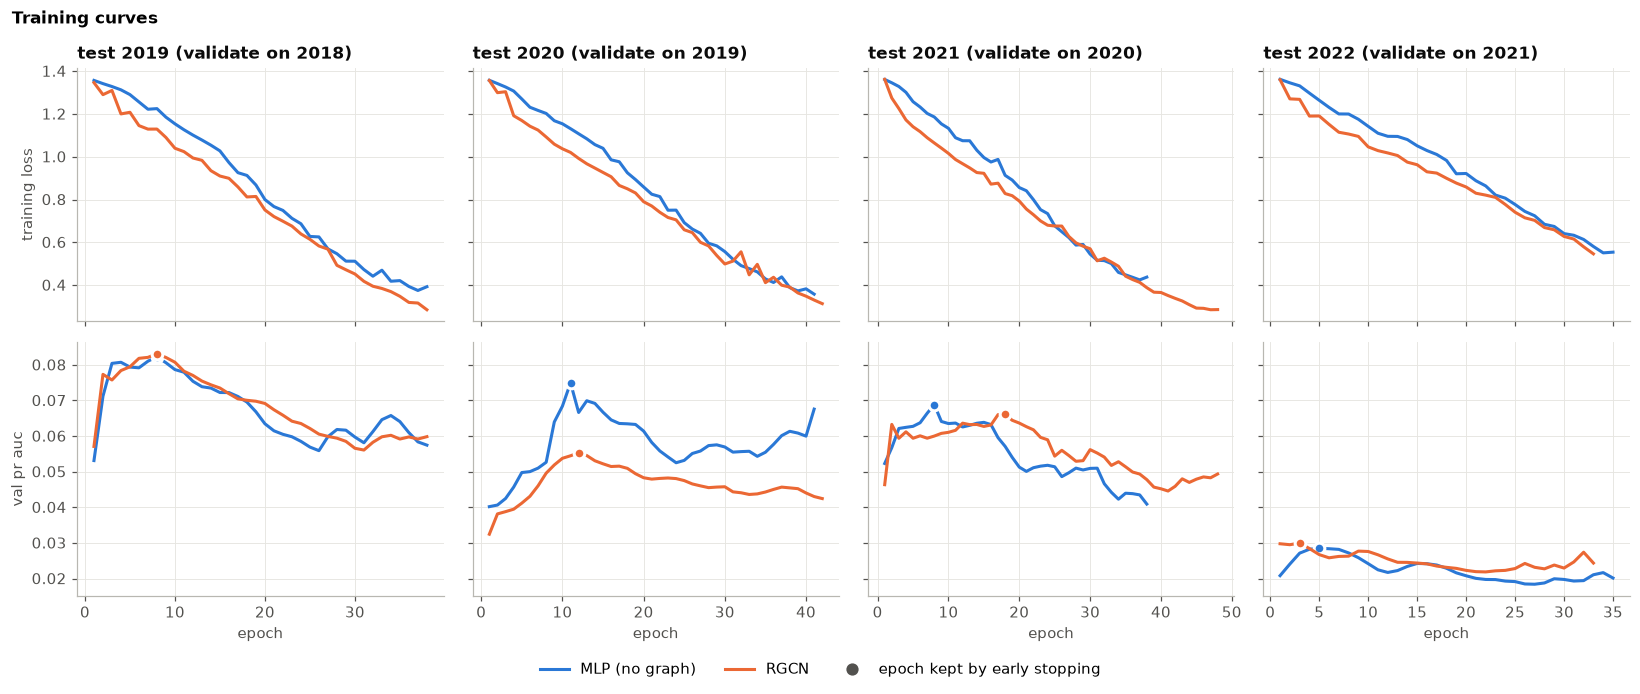

In [ ]:
# Training loss and validation PR-AUC per epoch for each test year
stop_column = f"val_{TRAINING_SETTINGS['stop_metric']}"
fig, axes = plt.subplots(2, len(TEST_YEARS), figsize=(15, 6), sharex="col", sharey="row")
for column, year in enumerate(TEST_YEARS):
    for model_name in TRAINED_MODELS:
        history = histories[(histories["model"] == model_name) & (histories["test_year"] == year)]
        # Epoch kept by early stopping
        best = history.loc[history[stop_column].idxmax()]
        axes[0, column].plot(history["epoch"], history["loss"], color=COLORS[model_name])
        axes[1, column].plot(history["epoch"], history[stop_column], color=COLORS[model_name])
        axes[1, column].plot(best["epoch"], best[stop_column], "o", markersize=7, color=COLORS[model_name], markeredgecolor="white", markeredgewidth=2)
    axes[0, column].set_title(f"test {year} (validate on {year - 1})")
    axes[1, column].set_xlabel("epoch")

axes[0, 0].set_ylabel("training loss")
axes[1, 0].set_ylabel(stop_column.replace("_", " "))
# Legend for both models and the best-epoch marker
handles = [Line2D([], [], color=COLORS[model_name], label=NAMES[model_name]) for model_name in TRAINED_MODELS]
handles.append(Line2D([], [], linestyle="", marker="o", markersize=7, color=INK_2, label="epoch kept by early stopping"))
fig.suptitle("Training curves", x=0.01, ha="left", fontsize=11, fontweight="bold")
fig.tight_layout()
fig.legend(handles=handles, loc="lower center", ncol=len(handles), bbox_to_anchor=(0.5, -0.05))
save_fig(fig, "training_curves")
plt.show()

### Confusion matrices
True and false positives when the top 5% of companies are flagged, for each model and year

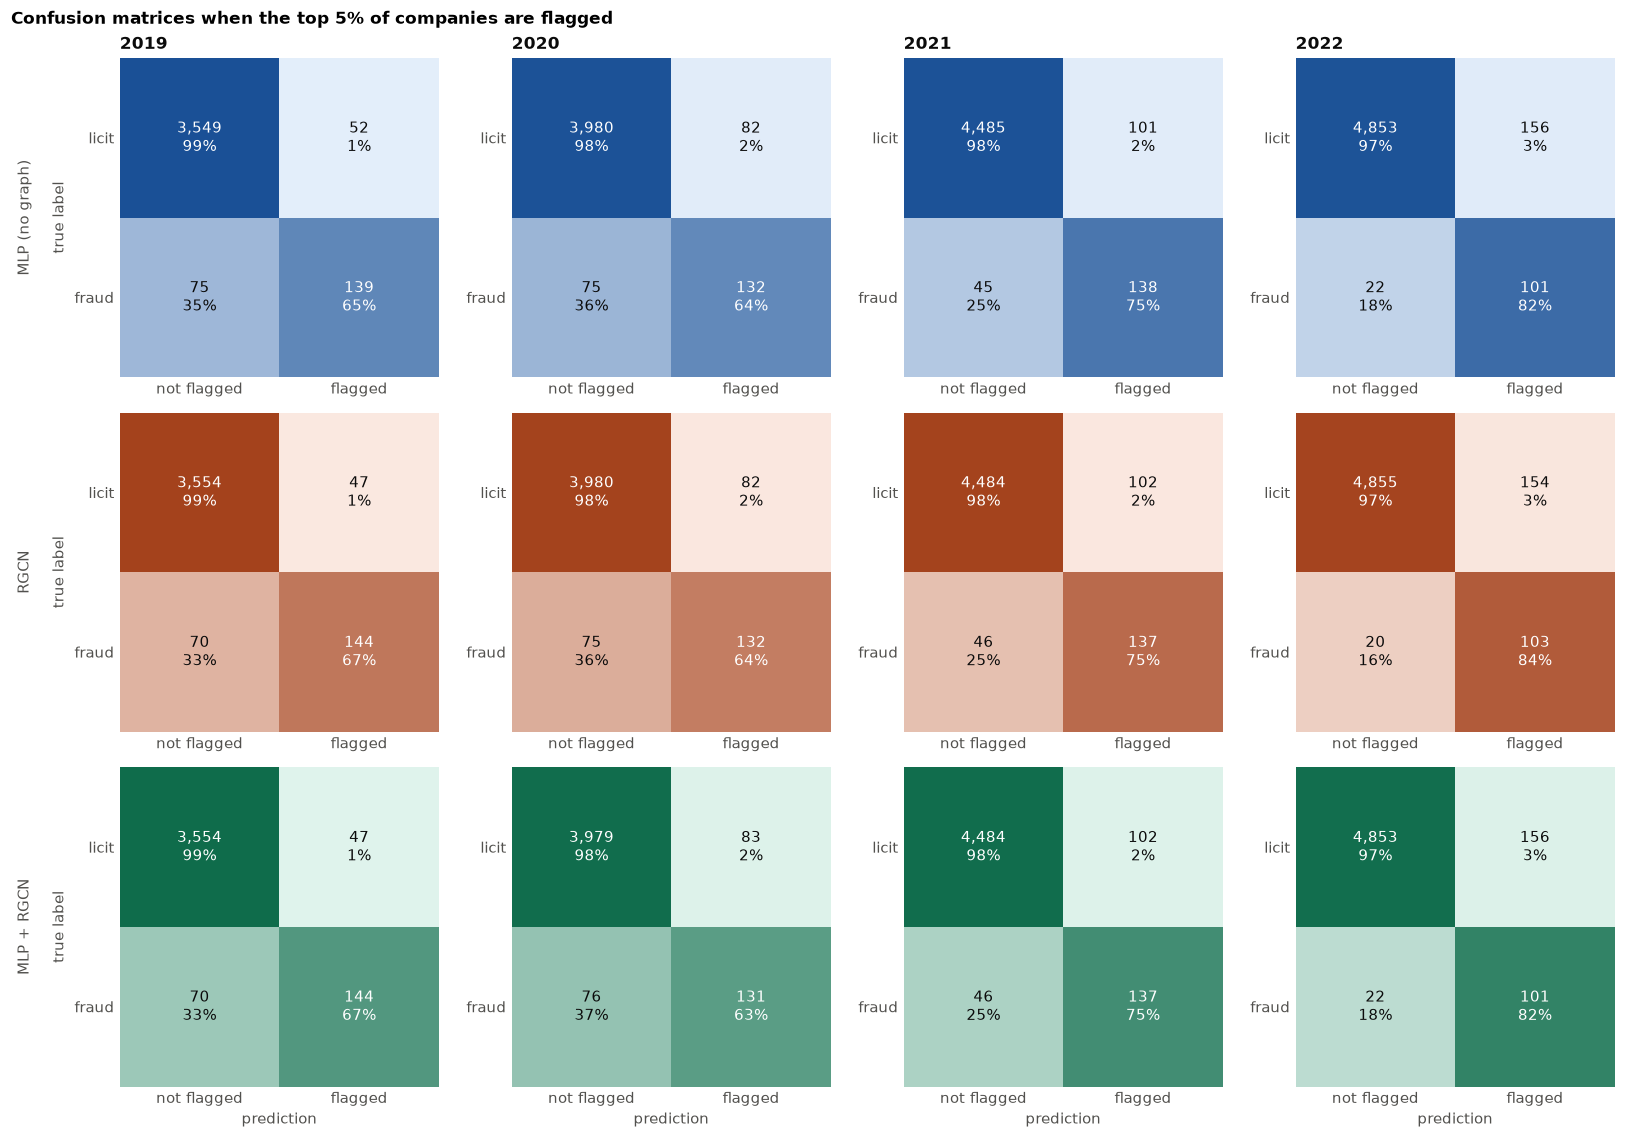

,model,test_year,TP,FP,FN,TN,precision,recall
0,MLP (no graph),2019,139,52,75,3549,0.728,0.650
1,MLP (no graph),2020,132,82,75,3980,0.617,0.638
2,MLP (no graph),2021,138,101,45,4485,0.577,0.754
3,MLP (no graph),2022,101,156,22,4853,0.393,0.821
4,RGCN,2019,144,47,70,3554,0.754,0.673
5,RGCN,2020,132,82,75,3980,0.617,0.638
6,RGCN,2021,137,102,46,4484,0.573,0.749
7,RGCN,2022,103,154,20,4855,0.401,0.837
8,MLP + RGCN,2019,144,47,70,3554,0.754,0.673
9,MLP + RGCN,2020,131,83,76,3979,0.612,0.633


In [ ]:
# Colour scale for each model
COLOR_RAMPS = {"mlp": ["#e6f0fc", "#184f95"], "rgcn": ["#fcebe3", "#a3401a"], "ens": ["#e2f5ee", "#0d6b4a"]}

# Confusion matrix per model and year when the top 5% are flagged
fig, axes = plt.subplots(len(MODELS), len(TEST_YEARS), figsize=(15, 3.5 * len(MODELS)))
confusion_rows = []
for row, model_name in enumerate(MODELS):
    color_map = LinearSegmentedColormap.from_list(model_name, COLOR_RAMPS[model_name])
    for column, year in enumerate(TEST_YEARS):
        rows = predictions_for(model_name, year)
        # Flag the top 5% of companies
        n_flagged = int(np.ceil(FLAG_SHARE * len(rows)))
        flagged = np.zeros(len(rows), dtype=int)
        flagged[np.argsort(-rows["score"].to_numpy())[:n_flagged]] = 1
        counts = confusion_matrix(rows["Label"], flagged, labels=[0, 1])
        shares = counts / counts.sum(axis=1, keepdims=True)

        # Show the counts and each true class's share
        ax = axes[row, column]
        ax.imshow(shares, cmap=color_map, vmin=0, vmax=1)
        for i in range(2):
            for j in range(2):
                ax.text(j, i, f"{counts[i, j]:,}\n{shares[i, j]:.0%}", ha="center", va="center", fontsize=10, color="white" if shares[i, j] > 0.5 else INK)
        ax.set(xticks=[0, 1], yticks=[0, 1], xticklabels=["not flagged", "flagged"], yticklabels=["licit", "fraud"])
        ax.grid(False)
        for spine in ax.spines.values():
            spine.set_visible(False)
        ax.tick_params(length=0)
        if row == 0:
            ax.set_title(str(year))
        if column == 0:
            ax.set_ylabel(f"{NAMES[model_name]}\n\ntrue label")
        if row == len(MODELS) - 1:
            ax.set_xlabel("prediction")

        # Keep the counts for the table
        true_negative, false_positive, false_negative, true_positive = counts.ravel()
        confusion_rows.append({"model": NAMES[model_name],
                               "test_year": year,
                               "TP": true_positive,
                               "FP": false_positive,
                               "FN": false_negative,
                               "TN": true_negative,
                               "precision": true_positive / (true_positive + false_positive),
                               "recall": true_positive / (true_positive + false_negative)})

fig.suptitle(f"Confusion matrices when the top {FLAG_SHARE:.0%} of companies are flagged", x=0.01, ha="left", fontsize=11, fontweight="bold")
fig.tight_layout()
save_fig(fig, "confusion_matrices")
plt.show()

# Save the table
confusion_table = pd.DataFrame(confusion_rows).round(3)
confusion_table.to_csv(RESULTS_DIR / "confusion_matrices.csv", index=False)
confusion_table

## Diagnostics
Checks on where the model succeeds and fails

### Repeat vs first-time frauds
How many flagged companies were fraudulent last year, and how many repeat and first-time frauds each model catches

In [ ]:
# Add last year's label to each test prediction
fraud_last_year_table = company_years.assign(Year=company_years["Year"] + 1).rename(columns={"Label": "fraud_last_year"})
diagnosis = (predictions.merge(fraud_last_year_table, on=KEYS, how="left").fillna({"fraud_last_year": 0}))
# Flag the top 5% by the first-time network's score
rank_in_year = diagnosis.groupby(["model", "Year"])["network_score"].rank(ascending=False, method="first")
year_size = diagnosis.groupby(["model", "Year"])["network_score"].transform("size")
diagnosis["flagged"] = rank_in_year <= np.ceil(FLAG_SHARE * year_size)
# Label each fraud as repeat or first-time
diagnosis["fraud_type"] = np.where(diagnosis["fraud_last_year"] == 1, "repeat fraud", "first-time fraud")

# Share of flagged companies that were fraudulent last year
display(diagnosis[diagnosis["flagged"]]
        .groupby(["Year", "model"])["fraud_last_year"]
        .mean()
        .unstack("model")[MODELS].rename(columns=NAMES)
        .round(3)
        .rename_axis(columns="share of flagged companies that were fraud last year"))

# Share of repeat and first-time frauds each model flags
(diagnosis[diagnosis["Label"] == 1]
 .groupby(["fraud_type", "Year", "model"])["flagged"]
 .mean()
 .unstack("model")[MODELS].rename(columns=NAMES)
 .round(3))

share of flagged companies that were fraud last year,MLP (no graph),RGCN,MLP + RGCN
Year,,,
2019,0.272,0.314,0.288
2020,0.285,0.290,0.313
2021,0.243,0.213,0.243
2022,0.179,0.167,0.167


model                  MLP (no graph)   RGCN  MLP + RGCN
fraud_type       Year                                   
first-time fraud 2019           0.125  0.161       0.143
                 2020           0.158  0.145       0.158
                 2021           0.106  0.085       0.106
                 2022           0.320  0.400       0.360
repeat fraud     2019           0.259  0.297       0.278
                 2020           0.344  0.351       0.359
                 2021           0.279  0.243       0.250
                 2022           0.276  0.286       0.276

### True positives at 5% under three rankings
Frauds caught using the model score only, last year's fraud first then the model score, and last year's fraud only

In [ ]:
# Frauds caught in the top 5% for a given score column
def true_positives(frame, score_column):
    groups = [frame["model"], frame["Year"]]
    rank = frame.groupby(groups)[score_column].rank(ascending=False, method="first")
    size = frame.groupby(groups)[score_column].transform("size")
    return (frame["Label"] * (rank <= np.ceil(FLAG_SHARE * size))).groupby(groups).sum()

# Three rankings: model only, last year's frauds first, last year's frauds only
ranked = diagnosis.assign(fraud_last_year_first=diagnosis["fraud_last_year"] + diagnosis["network_score"], fraud_last_year_only=diagnosis["fraud_last_year"])
(pd.concat({"model ranking": true_positives(ranked, "network_score"),
            "fraud last year first, then model": true_positives(ranked, "fraud_last_year_first"),
            "fraud last year only": true_positives(ranked, "fraud_last_year_only")}, axis=1)
   .unstack("model")
   .reindex(columns=MODELS, level="model")
   .rename(columns=NAMES))

model ranking                 fraud last year first, then model       \
model MLP (no graph) RGCN MLP + RGCN                    MLP (no graph) RGCN   
Year                                                                          
2019              48   56         52                               140  143   
2020              57   57         59                               132  132   
2021              43   37         39                               138  137   
2022              35   38         36                               101  103   

                 fraud last year only                  
model MLP + RGCN       MLP (no graph) RGCN MLP + RGCN  
Year                                                   
2019         142                  140  140        140  
2020         131                  131  131        131  
2021         137                  137  137        137  
2022         101                   98   98         98